# TS7: "Filtrado digital lineal de ECG"

## Alumnas: Irina Polack, Casandra Sotelino, Maylen Monterde y Lucila Suarez

En esta tarea semanal se nos pidio usar el archivo "ecg.mat", el cual contiene un registro electrocardiográfico (ECG) grabado a una frecuencia de muestreo $fs = 1000Hz$ durante una prueba de esfuerzo. El objetivo fue diseñar y aplicar filtros digitales necesarios para poder mitigar las fuentes de contaminación que deterioran la señal, como lo pueden ser: el ruido causado por el movimiento de los electrodos y el ruido muscular (ambos de alta frecuencia), y el movimiento de la línea de base del ECG, inducido en parte por la respiración (baja frecuencia). Para lograrlo, se estableció una plantilla de diseño que se fue ajustando para no distorsionar la señal y poder filtrar las interferencias fuera del ancho de banda de la señal ("BW").


Los filtros digitales se clasifican en dos grandes grupos según su respuesta al impulso: los IIR (respuesta infinita al impulso) y los FIR (respuesta finita). 
Los IIR se caracterizan por cumplir una plantilla dada con un orden mucho menor que los FIR, lo que los hace eficientes en costo computacional. Sin embargo, al ser recursivos poseen polos fuera del origen en el plano z, por lo que se requiere que todos sus polos estén estrictamente dentro del círculo unitario para garantizar estabilidad. En este trabajo se utilizaron los filtros Butterworth y Chebyshev tipo II. 


**Filtro Butterworth:**

Su respuesta en magnitud analógica de máxima planicidad en la banda de paso: $$\vert{}H_a(j\Omega)\vert{}^2 = \frac{1}{1 + \left(\frac{\Omega}{\Omega_c}\right)^{2N}}$$

Polos en el plano $s$:

Se continua analíticamente reemplazando $s = j\Omega$, lo que da:


$H_a(s)H_a(-s) = \frac{1}{1 + (-s^2/\Omega_c^2)^N}$. Los polos están dados por:$$s_k = \Omega_c \exp\left(j \left[ \frac{\pi}{2} + \frac{(2k - 1)\pi}{2N} \right]\right), \quad k = 1, 2, \dots, N \quad (\text{semiplano izquierdo})$$



Transformación Bilineal (Mapeo a $z$):

Para pasar al dominio digital se aplica la sustitución con pre-warping (para que no se deforme el eje de frecuencias) $\Omega = \frac{2}{T} \tan\left(\frac{\omega}{2}\right)$:

$$s = \frac{2}{T} \frac{1 - z^{-1}}{1 + z^{-1}}$$$$H(z) = H_a(s) \Big\vert{}_{s = \frac{2}{T} \frac{1 - z^{-1}}{1 + z^{-1}}}$$


**Filtro Chebyshev tipo II:**

Tiene una magnitud: 
$$\vert{}H_a(j\Omega)\vert{}^2 = \frac{1}{1 + \frac{1}{\epsilon^2 T_N^2(\Omega_r / \Omega)}} = \frac{\epsilon^2 T_N^2(\Omega_r / \Omega)}{1 + \epsilon^2 T_N^2(\Omega_r / \Omega)}$$
donde $T_N(x)$ es el polinomio de Chebyshev de orden $N$, $\Omega_r = \Omega_s/\Omega_p$, y $\epsilon$ define la atenuación mínima en la banda de detención ($A_s = 10\log_{10}(1 + 1/\epsilon^2)$).

Polos y Ceros en el plano $s$:

Ceros (nulos de atenuación): Ocurren en las raíces de $T_N(\Omega_r / \Omega) = 0$:$$z_k = j \frac{\Omega_r}{\cos\left(\frac{(2k-1)\pi}{2N}\right)}, \quad k = 1, 2, \dots, N$$


Polos: Inversos a los polos de Chebyshev Tipo I ($p_k^{TipoII} = \frac{\Omega_r \Omega_c}{p_k^{TipoI}}$).


Mapeo Digital:
Se mapea al plano $z$ mediante la Transformación Bilineal con pre-warping de frecuencia:$$H(z) = H_a(s) \Big\vert{}_{s = \frac{2}{T} \frac{1 - z^{-1}}{1 + z^{-1}}}$$


Por otro lado, los FIR (Finite Impulse Response) siempre son estables debido a que sus polos estan en el origen. Ademas, se pueden usar en tiempo real y es mas simple que tengan una fase lineal; esto garantiza que todos los componentes espectrales de la señal sufran el mismo retardo temporal, evitando distorciones de la misma.


En este trabajo se implementaron tres tipos de FIR:


**Método de ventanas:**



Es una técnica estadística que se utiliza para encontrar la mejor aproximación de un conjunto de datos minimizando la suma de los cuadrados de las diferencias entre los valores observados y los valores predichos por el modelo. En el contexto de filtros FIR, el objetivo es diseñar un filtro que minimice el error entre la respuesta del filtro y una respuesta deseada. 
Este tipo de filtros ofrecen una buena aproximación de la respuesta deseada, pero tienden a presentar un comportamiento diferente en comparación con otros métodos.

El objetivo es minimizar el error cuadrático entre la respuesta en frecuencia del filtro $H_R(\Omega)$ y la respuesta deseada $D(\Omega)$:

$$|E(\Omega)|^2 = \sum_{\Omega \in F} |D(\Omega) - H_R(\Omega)|^2$$

Como se verá más adelante, este problema se puede resolver de forma práctica mediante álgebra matricial en cualquier lenguaje de programación.

Se define la respuesta deseada $D(\Omega)$ en la banda de frecuencia, donde $\Omega$ es la frecuencia angular normalizada (de $0$ a $\pi$). La respuesta deseada del filtro en frecuencia $D(\Omega)$ puede definirse como:

$$D(\Omega) = \begin{cases} 
1 & \text{si } 0 \le \Omega \le \Omega_c \\ 
0 & \text{si } \Omega_c < \Omega \le 1.0 
\end{cases}$$



**Método de Parks-McClellan:**



El algoritmo de Parks-McClellan (PM) es una herramienta poderosa utilizada para diseñar filtros FIR óptimos en términos de la minimización del error máximo en las bandas de frecuencia de interés. Se entiende al error como la diferencia entre una respuesta deseada (e.g. plantilla del filtro) y la obtenida por el algoritmo PM. Es decir que éste algoritmo distribuye el error de manera acotada en toda la banda de frecuencia, razón por la cual se lo suele denominar como error de Chebyshev o equirriple. La fundamentación matemática de este algoritmo se basa en el método de la alternancia de Remez, y una búsqueda iterativa de las frecuencias extremas que acotan la señal de error. 


Para poder diseñar y aplicar los filtros mencionados de manera adecuada, se realizo una plantilla de diseño que se fue modificando con el criterio que las señales filtradas no quedaran sobre el ancho de banda util. Esta plantilla quedo como frecuencias de rechazo y paso inferior ws1 = 0.1 Hz y wp1 = 1 Hz; frecuencias de paso y rechazo superior wp2 = 35 Hz y ws2 = 50 Hz. Y por ultimo, parametros de atenuacion Gpass = 3 dB y Gstop = 40 dB.

### RESOLUCIÓN:

Tipo: <class 'numpy.ndarray'>
Forma (shape): (30000,)


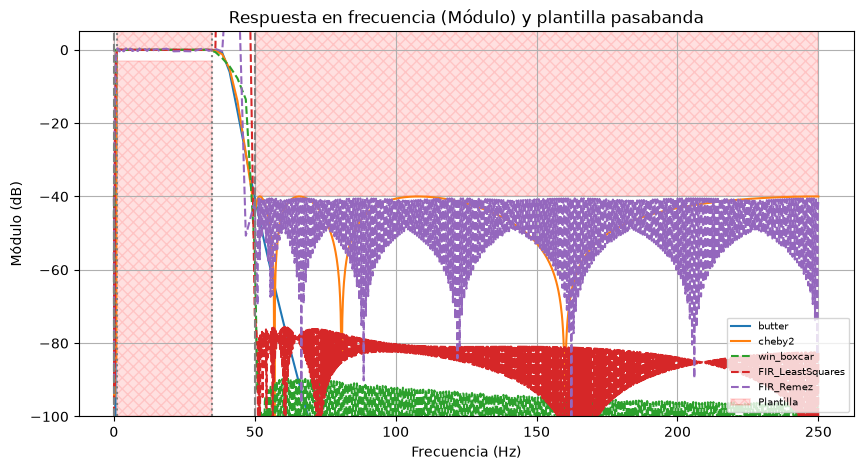

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig
from matplotlib.patches import Rectangle 
import scipy.io as sio

ruta_npy = './ecg_sin_ruido.npy'
ecg_sin_ruido = np.load(ruta_npy)

print("Tipo:", type(ecg_sin_ruido))
print("Forma (shape):", ecg_sin_ruido.shape)

mat_path = './ECG_TP4.mat'
sio.whosmat(mat_path)
mat_struct = sio.loadmat(mat_path)
ecg_one_lead = mat_struct['ecg_lead']

# Definición de parámetros (Pasabanda)
fs_ecg = 500
wp1 = 1    #[Hz]
ws1 = 0.1   #[Hz]  
wp2 = 35   #[Hz]
ws2 = 50   #[Hz]
Gpass = 3
Gstop = 40

ripple = Gpass
att = Gstop

# Definición del vector de frecuencias personalizado
ff = np.append(np.logspace(np.log10(.001), np.log10(2), 2000), np.logspace(np.log10(2.01), np.log10(50)))
ff = np.append(ff, np.linspace(51, fs_ecg/2, 1000, endpoint=True))

# Funciones auxiliares para el cálculo de frecuencia
def calc_freq_sos(sos):
    resp_freq = sig.freqz_sos(sos, worN=ff, fs=fs_ecg)
    return resp_freq

def calc_freq_fir(bfir):
    resp_freq = sig.freqz(bfir, 1, worN=ff, fs=fs_ecg)
    return resp_freq

# Diseño de los filtros en formato SOS
orden_butter = 4
sos_butt = sig.iirdesign([wp1, wp2+5], [ws1, ws2], Gpass, Gstop, ftype='butter', fs=fs_ecg, output='sos')
sos_cheby2 = sig.iirdesign([wp1, wp2+5], [ws1, ws2], Gpass, Gstop, ftype='cheby2', fs=fs_ecg, output='sos')
#sos_cauer = sig.iirdesign([wp1, wp2], [ws1, ws2], Gpass, Gstop, ftype='cauer', fs=fs_ecg, output='sos')

# FIR design (Ventanas)
taps_win = 2000
b_win_boxcar = sig.firwin2(taps_win+20, [0.0, ws1+0.15, wp1-0.3, wp2, ws2, fs_ecg/2], [0.0, 0.0, 1.0, 1.0, 0.0, 0.0], fs=fs_ecg, window="boxcar")
#b_win_Hamming = sig.firwin2(taps_win, [0.0, ws1+0.3, wp1, wp2, ws2, fs_ecg/2], [0.0, 0.0, 1.0, 1.0, 0.0, 0.0], fs=fs_ecg, window="hamming")

# FIR design (Mínimos Cuadrados - firls requiere número de taps impar)
b_firls = sig.firls(1251, [0.0, ws1+0.25, wp1, wp2+1.5, ws2, fs_ecg/2], [0.0, 0.0, 1.0, 1.0, 0.0, 0.0], fs=fs_ecg)

# FIR design (Remez / Equiripple - orden moderado para asegurar convergencia)
# %%
b_remez = sig.remez(631,[0.0, ws1, wp1, wp2+5, ws2-5, fs_ecg/2], [0.0, 1.0, 0.0], weight=[5, 1, 5], fs=fs_ecg)

y_min, y_max = -100, 5

#%% Graficar la respuesta en frecuencia (Módulo y Plantilla)
plt.close('all')

fig, ax_mod = plt.subplots(figsize=(10, 5))

# Graficamos los módulos de los filtros IIR
for sos, name in zip([sos_butt, sos_cheby2], ['butter', 'cheby2']): #acá se borró Cauer
    f, h = calc_freq_sos(sos)
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=name)

# Graficamos los filtros FIR (Ventanas, Mínimos Cuadrados y Remez)
fir_filters = [
    (b_win_boxcar, 'win_boxcar'), 
    #(b_win_Hamming, 'win_Hamming'), 
    (b_firls, 'FIR_LeastSquares'),
    (b_remez, 'FIR_Remez')
]

for b_fir, name in fir_filters:
    f, h = calc_freq_fir(b_fir)
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    ax_mod.plot(f, modulo_db, linewidth=1.5, linestyle='--', label=name)

ax_mod.set_ylim(y_min, y_max)
ax_mod.set_ylabel("Módulo (dB)")
ax_mod.set_xlabel("Frecuencia (Hz)")
ax_mod.set_title("Respuesta en frecuencia (Módulo) y plantilla pasabanda")
ax_mod.grid(True)

# Plantilla pasabanda
rect_rechazo_inf = Rectangle(
    (0, -att), ws1, y_max + att,
    facecolor="red", alpha=0.12, edgecolor="red", hatch="xxx", linewidth=1.2, label='Plantilla'
)
ax_mod.add_patch(rect_rechazo_inf)

rect_rechazo_sup = Rectangle(
    (ws2, -att), fs_ecg / 2 - ws2, y_max + att,
    facecolor="red", alpha=0.12, edgecolor="red", hatch="xxx", linewidth=1.2
)
ax_mod.add_patch(rect_rechazo_sup)

rect_paso_inf = Rectangle(
    (wp1, y_min), wp2 - wp1, -Gpass - y_min,
    facecolor="red", alpha=0.12, edgecolor="red", hatch="xxx", linewidth=1.2
)
ax_mod.add_patch(rect_paso_inf)

rect_paso_sup = Rectangle(
    (wp1, 0), wp2 - wp1, y_max - 0,
    facecolor="red", alpha=0.12, edgecolor="red", hatch="xxx", linewidth=1.2
)
ax_mod.add_patch(rect_paso_sup)

ax_mod.axvline(wp1, color="gray", linestyle=":")
ax_mod.axvline(wp2, color="gray", linestyle=":")
ax_mod.axvline(ws1, color="gray", linestyle="--")
ax_mod.axvline(ws2, color="gray", linestyle="--")
ax_mod.legend(loc="lower right", fontsize=7)
plt.show()

- Para poder analizar mejor el gráfico, le aplicamos zoom a las distintas regiones:

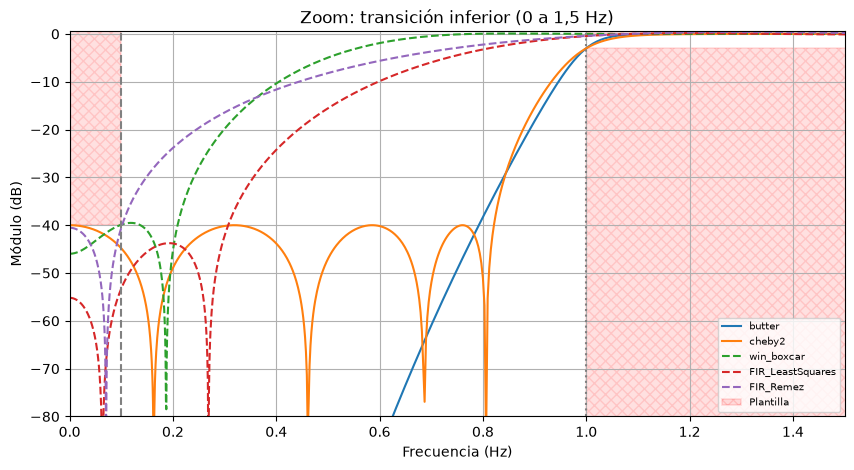

In [3]:
##ZOOM 1:
ax_mod.set_xlim(0, 1.5)
ax_mod.set_ylim(-80, 0.5)
ax_mod.set_title("Zoom: transición inferior (0 a 1,5 Hz)")
fig


**Observaciones:**


Se cumple con lo esperado, en el rechazo de 0-0,1Hz se observa: 
- Butterworth (azul) cumple con mucho margen, en 0,6Hz está por debajo de los -80dB.
- Chebyshev II (naranja) cumple con lo justo: el ripple toca los -40dB que es exactamente la atenuación de diseño.
- Cuadrados mínimos (rojo) cumple con margen.
- Boxcar (verde) y Remez (violeta) quedan al límite. A 0,1Hz están practicamente sobre los -40dB.


Luego en el borde de la banda de paso se observa que los IIR valen alrededor de -3dB a partir de 1Hz aproximadamente. En cambio, los FIR alcanzan la banda de paso antes de 1Hz, por lo que atenúan menos la zona de baja frecuencia (entre 0,2-0,5Hz).

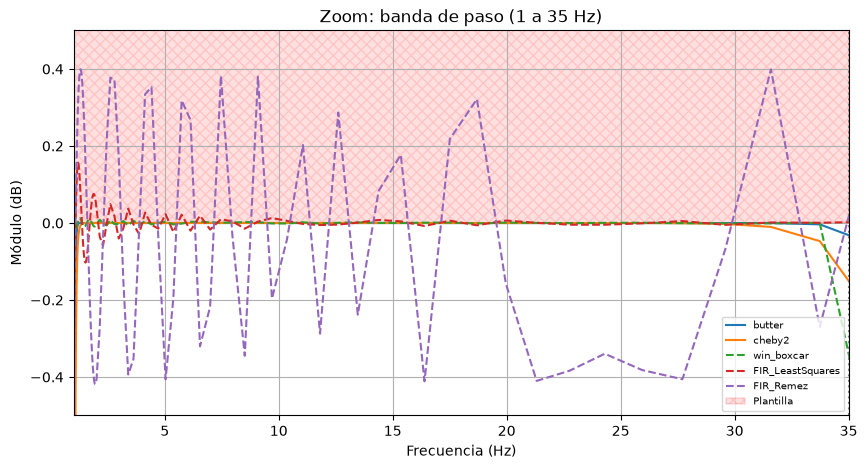

In [4]:
##ZOOM 2:
ax_mod.set_xlim(1, 35)
ax_mod.set_ylim(-0.5, 0.5)
ax_mod.set_title("Zoom: banda de paso (1 a 35 Hz)")
fig

**Observaciones:**


Los IIR tienen la banda de paso practicamente plana, sin ripple como era de esperarse. Se observa que los FIR si presentan ripple, cuadrados mínimos es casi plano con un ripple menor a 0.2dB; la ventana rectangular tambien presenta un ripple que va cayendo; el más notorio es en el caso de Remez, donde presenta un equirriple de aproximadamente +/- 0,4dB distribuido de manera uniforme en toda la banda de paso. Diferenciandose, asi, de los filtros IIR y el de cuadrados minimos que mantienen una respuesta mucho mas horizontal, plana y libre de ondulaciones en esa misma zona, como se observa en el grafico. Esa diferencia sucede a que el filtro Remez se basa en el criterio de minimax, el cual minimiza el maximo error. 

Otra cosa a observar es el aspecto irregular de la curva de Remez, esto se debe a la resolución de frecuencias utilizado para graficar.

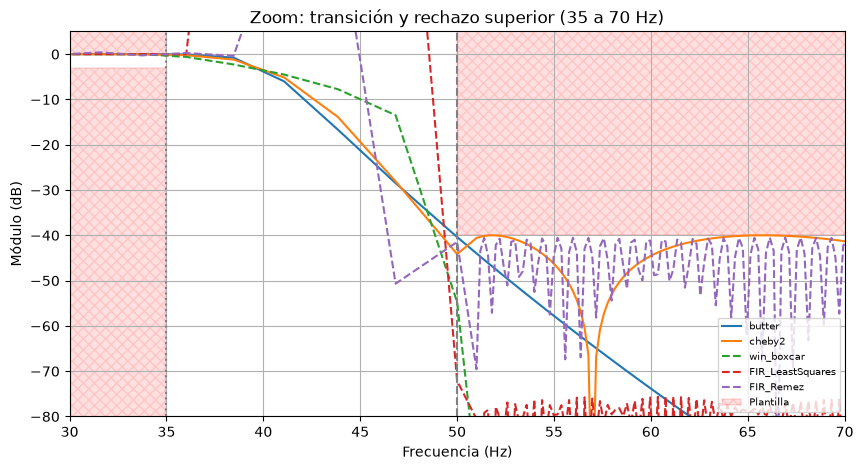

In [5]:
##ZOOM 3:
ax_mod.set_xlim(30, 70)
ax_mod.set_ylim(-80, 5)
ax_mod.set_title("Zoom: transición y rechazo superior (35 a 70 Hz)")
fig

**Observaciones:**


A partir de 50Hz, donde comienza la banda de rechazo, todos los filtros cumplen con los -40dB pedidos.

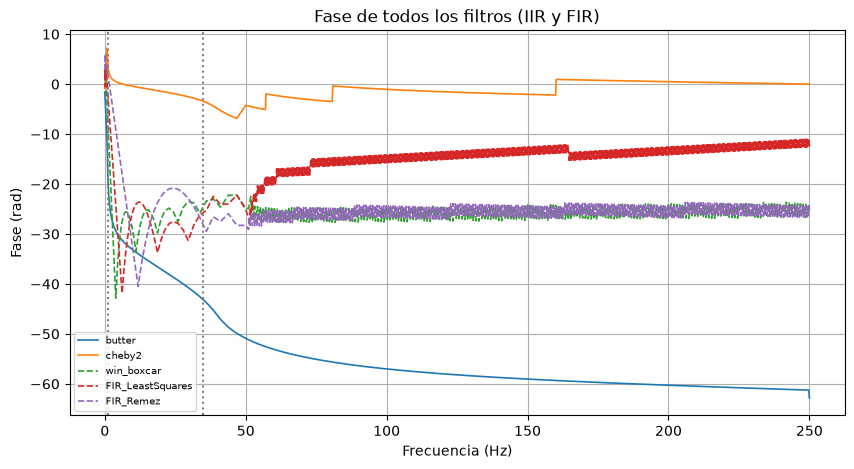

In [6]:
#%% FASE DE TODOS LOS FILTROS EN UN MISMO GRÁFICO (IIR y FIR)
plt.figure(figsize=(10, 5))

# Fase filtros IIR
for sos, name in zip([sos_butt, sos_cheby2], ['butter', 'cheby2']):
    f, h = calc_freq_sos(sos)
    fase_rad = np.unwrap(np.angle(h))
    plt.plot(f, fase_rad, linewidth=1.2, label=name)

# Fase todos los filtros FIR
for b_fir, name in fir_filters:
    f, h = calc_freq_fir(b_fir)
    fase_rad = np.unwrap(np.angle(h))
    plt.plot(f, fase_rad, linewidth=1.2, linestyle='--', label=name)

plt.axvline(wp1, color="gray", linestyle=":")
plt.axvline(wp2, color="gray", linestyle=":")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Fase (rad)")
plt.title("Fase de todos los filtros (IIR y FIR)")
plt.grid(True)
plt.legend(loc='lower left', fontsize=7)
plt.show()

**Observaciones:**


Se puede observar que Butter tiene una fase con una pendiente mayor a las demás (negativa), luego cuadrados mínimos tiene una pendiente mayor positiva, los filtros FIR presentan una oscilación entre 0 y 50 hz mientras que los IIR no, Cheby es el que se mantiene más constante a toda frecuencia, mientras que los filtros Remez y rectangular están casi totalmente constantes en -30 luego de los 50 hz

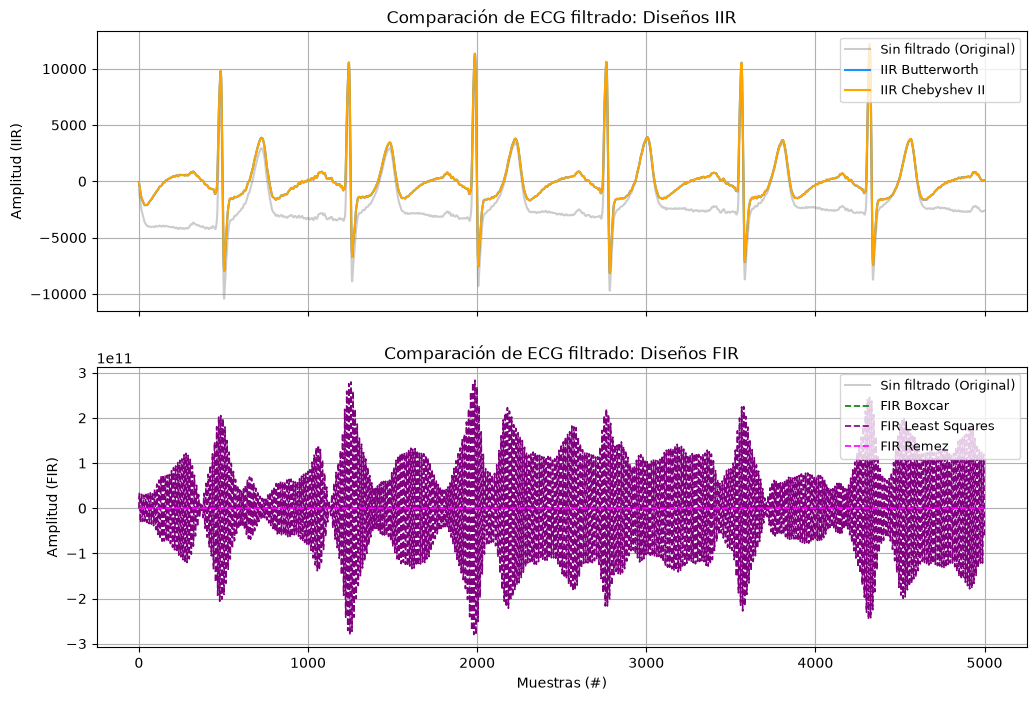

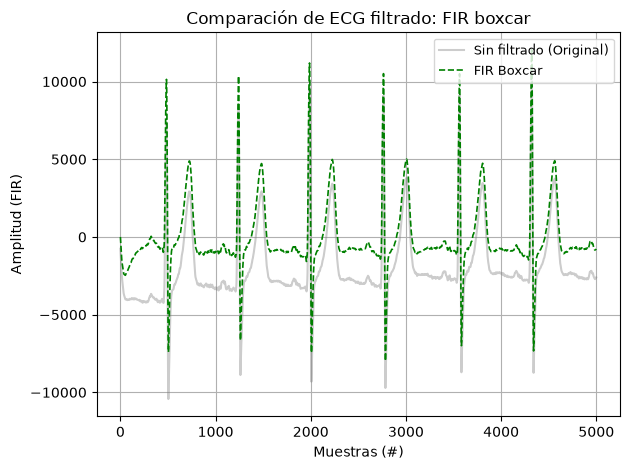

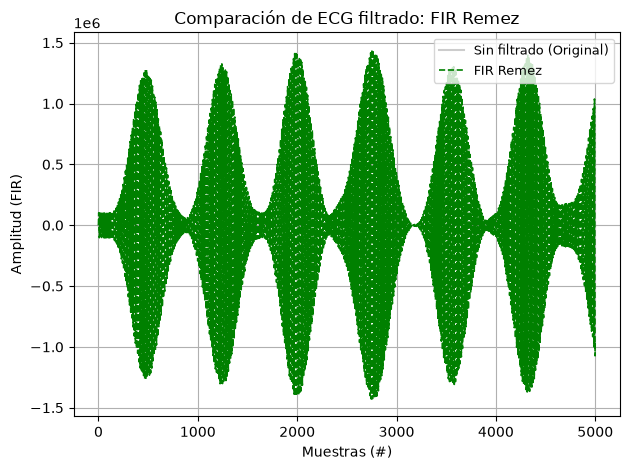

In [7]:
#%% APLICACIÓN Y FILTRADO DEL ECG (TODOS LOS FILTROS CON SUBPLOTS)
ecg_flat = ecg_one_lead.flatten()

# --- Filtrado IIR (sosfiltfilt para fase cero) ---
ecg_filt_butt = sig.sosfiltfilt(sos_butt, ecg_flat)
ecg_filt_cheby2 = sig.sosfiltfilt(sos_cheby2, ecg_flat)
# ecg_filt_cauer = sig.sosfiltfilt(sos_cauer, ecg_flat)  # Descomentar si usás Cauer

# --- Filtrado FIR (filtfilt para fase cero) ---
ecg_filt_boxcar = sig.filtfilt(b_win_boxcar, 1, ecg_flat)
ecg_filt_firls = sig.filtfilt(b_firls, 1, ecg_flat)
ecg_filt_remez = sig.filtfilt(b_remez, 1, ecg_flat)

# Definición del tramo a graficar
N_plot = min(5000, len(ecg_flat))
muestras_plot = np.arange(N_plot)

# Creamos una figura con 2 subplots (compartiendo el eje X) para aislar escalas
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# --- Panel Superior: Señal Original y Filtros IIR ---
ax1.plot(muestras_plot, ecg_flat[:N_plot], color='gray', alpha=0.4, linewidth=1.5, label='Sin filtrado (Original)')
ax1.plot(muestras_plot, ecg_filt_butt[:N_plot], color='dodgerblue', linewidth=1.5, label='IIR Butterworth')
ax1.plot(muestras_plot, ecg_filt_cheby2[:N_plot], color='orange', linewidth=1.5, label='IIR Chebyshev II')
ax1.set_ylabel('Amplitud (IIR)')
ax1.set_title('Comparación de ECG filtrado: Diseños IIR')
ax1.grid(True)
ax1.legend(loc='upper right', fontsize=9)

# --- Panel Inferior: Señal Original y Filtros FIR ---
ax2.plot(muestras_plot, ecg_flat[:N_plot], color='gray', alpha=0.4, linewidth=1.5, label='Sin filtrado (Original)')
ax2.plot(muestras_plot, ecg_filt_boxcar[:N_plot], color='green', linestyle='--', linewidth=1.2, label='FIR Boxcar')
ax2.plot(muestras_plot, ecg_filt_firls[:N_plot], color='purple', linestyle='--', linewidth=1.2, label='FIR Least Squares')
ax2.plot(muestras_plot, ecg_filt_remez[:N_plot], color='magenta', linestyle='--', linewidth=1.2, label='FIR Remez')
ax2.set_ylabel('Amplitud (FIR)')
ax2.set_xlabel('Muestras (#)')
ax2.set_title('Comparación de ECG filtrado: Diseños FIR')
ax2.grid(True)
ax2.legend(loc='upper right', fontsize=9)

plt.figure(2)
plt.plot(muestras_plot, ecg_flat[:N_plot], color='gray', alpha=0.4, linewidth=1.5, label='Sin filtrado (Original)')
plt.plot(muestras_plot, ecg_filt_boxcar[:N_plot], color='green', linestyle='--', linewidth=1.2, label='FIR Boxcar')
plt.ylabel('Amplitud (FIR)')
plt.xlabel('Muestras (#)')
plt.title('Comparación de ECG filtrado: FIR boxcar')
plt.grid(True)
plt.legend(loc='upper right', fontsize=9)
plt.tight_layout()

plt.figure(3)
plt.plot(muestras_plot, ecg_flat[:N_plot], color='gray', alpha=0.4, linewidth=1.5, label='Sin filtrado (Original)')
plt.plot(muestras_plot, ecg_filt_remez[:N_plot], color='green', linestyle='--', linewidth=1.2, label='FIR Remez')
plt.ylabel('Amplitud (FIR)')
plt.xlabel('Muestras (#)')
plt.title('Comparación de ECG filtrado: FIR Remez')
plt.grid(True)
plt.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

Se puede observar que en el caso de los filtros IIR, se está filtrando la señal correctamentem mientras que en los FIR Remez y cuadrados mínimos nos está amplificando ciertas partes, lo cual nos deja con un efecto no deseado. Esto probablemente sucede por la cantidad de coeficientes que utilizamos. Aunque en la boxcar en una mayor cantidad de coeficientes no divergió sino que la ECG quedó filtrada. En este caso, los filtros que mejor actuaron fueron los de Butter, Cheby2 y Boxcar. 

### CONCLUSIÓN:

Podemos decir que los que mejor aproximan son los filtros de Butter y de Cuadrados minimos. Porque, el primero tiene una maxima planitud. Y el segundo, por presentar un ripple menor a 0.2 dB en la banda de paso y mantener fase lineal. 